In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


# ### Load Dataset

In [2]:
df = pd.read_csv("marketing_campaign.csv")
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04/09/2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08/03/2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21/08/2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10/02/2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19/01/2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


In [3]:
####he purpose of EDA is to understand customer demographics, spending patterns, purchasing channels, recency, and campaign behavior, while also identifying missing values, outliers, duplicates, and other data-quality issues.
##These findings guide our feature engineering and preprocessing before applying K-Means clustering.”

In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 2240
Number of columns: 29


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

#### Statistical Summary

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0


In [7]:
df.columns.tolist()

['ID',
 'Year_Birth',
 'Education',
 'Marital_Status',
 'Income',
 'Kidhome',
 'Teenhome',
 'Dt_Customer',
 'Recency',
 'MntWines',
 'MntFruits',
 'MntMeatProducts',
 'MntFishProducts',
 'MntSweetProducts',
 'MntGoldProds',
 'NumDealsPurchases',
 'NumWebPurchases',
 'NumCatalogPurchases',
 'NumStorePurchases',
 'NumWebVisitsMonth',
 'AcceptedCmp3',
 'AcceptedCmp4',
 'AcceptedCmp5',
 'AcceptedCmp1',
 'AcceptedCmp2',
 'Complain',
 'Z_CostContact',
 'Z_Revenue',
 'Response']

##### Data Quality Analysis

In [8]:
missing_values = df.isnull().sum()

missing_table = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": (missing_values / len(df) * 100).round(2)
})

missing_table[missing_table["Missing Values"] > 0].sort_values(
    "Missing Values",
    ascending=False
)

,Missing Values,Percentage
Income,24,1.07


#### 24 observations have missing Income values, representing approximately 1.07% of the dataset.

## Duplicate Records

In [9]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [10]:
df.dtypes

ID                       int64
Year_Birth               int64
Education                  str
Marital_Status             str
Income                 float64
Kidhome                  int64
Teenhome                 int64
Dt_Customer                str
Recency                  int64
MntWines                 int64
MntFruits                int64
MntMeatProducts          int64
MntFishProducts          int64
MntSweetProducts         int64
MntGoldProds             int64
NumDealsPurchases        int64
NumWebPurchases          int64
NumCatalogPurchases      int64
NumStorePurchases        int64
NumWebVisitsMonth        int64
AcceptedCmp3             int64
AcceptedCmp4             int64
AcceptedCmp5             int64
AcceptedCmp1             int64
AcceptedCmp2             int64
Complain                 int64
Z_CostContact            int64
Z_Revenue                int64
Response                 int64
dtype: object

#### Feature Engineering for EDA

### Total Spending

In [11]:
product_cols = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

df["Total_Spending"] = df[product_cols].sum(axis=1)

df[["Total_Spending"] + product_cols].head()

,Total_Spending,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds
0,1617,635,88,546,172,88,88
1,27,11,1,6,2,1,6
2,776,426,49,127,111,21,42
3,53,11,4,20,10,3,5
4,422,173,43,118,46,27,15


### Total Purchases

In [12]:
purchase_cols = [
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases"
]

df["Total_Purchases"] = df[purchase_cols].sum(axis=1)

df[["Total_Purchases"] + purchase_cols].head()

,Total_Purchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases
0,22,8,10,4
1,4,1,1,2
2,20,8,2,10
3,6,2,0,4
4,14,5,3,6


### Total Children

In [13]:
df["Total_Children"] = df["Kidhome"] + df["Teenhome"]

df[["Kidhome", "Teenhome", "Total_Children"]].head()

,Kidhome,Teenhome,Total_Children
0,0,0,0
1,1,1,2
2,0,0,0
3,1,0,1
4,1,0,1


#### Campaign Acceptance

In [14]:
campaign_cols = [
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "Response"
]

df["Total_Campaign_Acceptance"] = df[campaign_cols].sum(axis=1)

df[["Total_Campaign_Acceptance"] + campaign_cols].head()

,Total_Campaign_Acceptance,AcceptedCmp1,AcceptedCmp2,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,Response
0,1,0,0,0,0,0,1
1,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0


#### Education Distribution

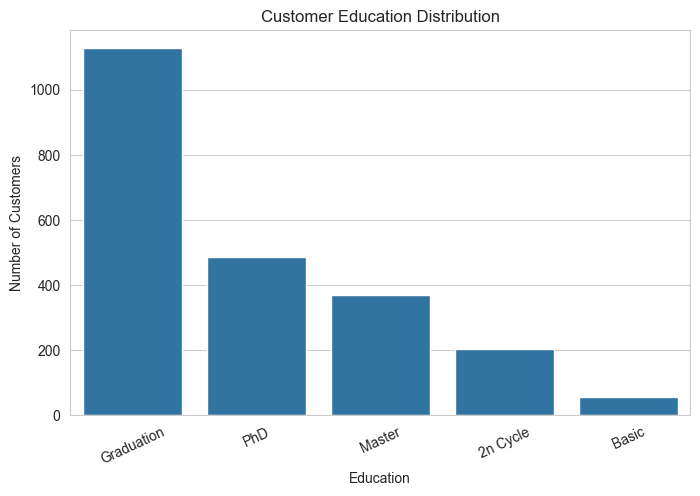

In [15]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Education",
    order=df["Education"].value_counts().index
)

plt.title("Customer Education Distribution")
plt.xlabel("Education")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25)

plt.show()

### Marital Status

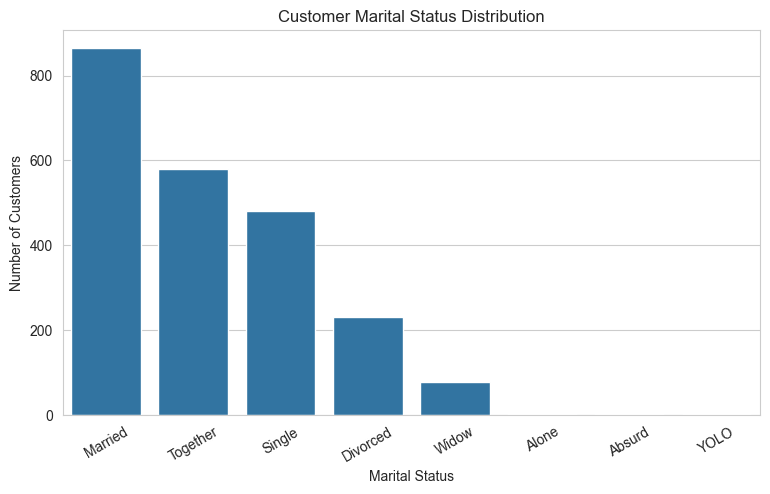

In [16]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Marital_Status",
    order=df["Marital_Status"].value_counts().index
)

plt.title("Customer Marital Status Distribution")
plt.xlabel("Marital Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)

plt.show()

### Income Distribution

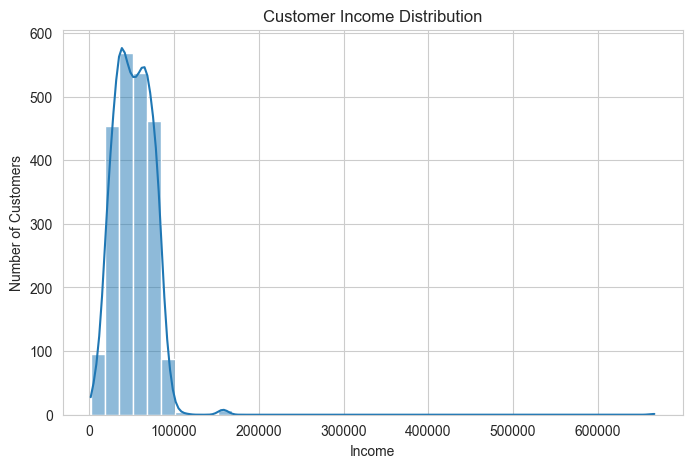

In [17]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Income",
    bins=40,
    kde=True
)

plt.title("Customer Income Distribution")
plt.xlabel("Income")
plt.ylabel("Number of Customers")

plt.show()

### Age Feature

In [18]:
df["Age"] = 2014 - df["Year_Birth"]

df["Age"].describe()

count    2240.000000
mean       45.194196
std        11.984069
min        18.000000
25%        37.000000
50%        44.000000
75%        55.000000
max       121.000000
Name: Age, dtype: float64

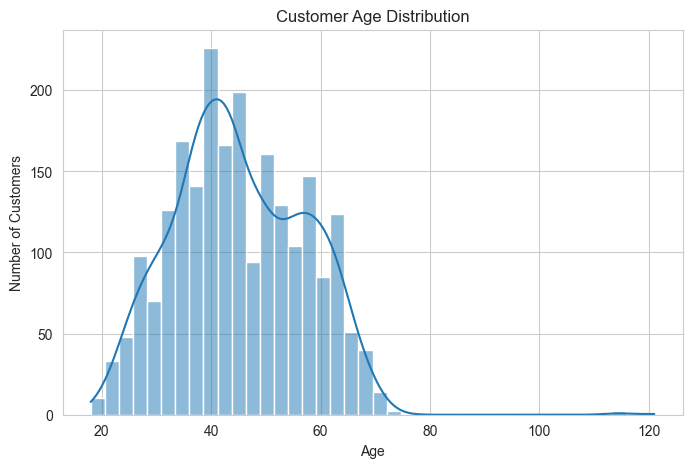

In [19]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=40,
    kde=True
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

#### Average Spending by Product

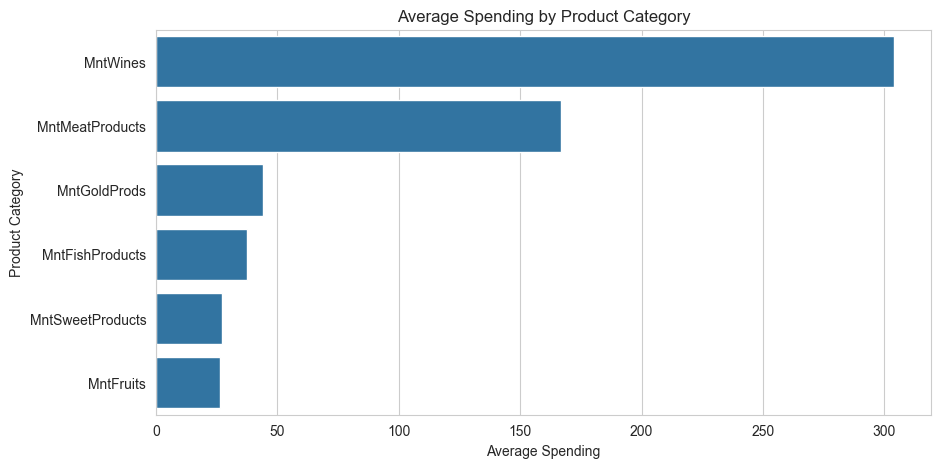

In [20]:
average_spending = df[product_cols].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=average_spending.values,
    y=average_spending.index
)

plt.title("Average Spending by Product Category")
plt.xlabel("Average Spending")
plt.ylabel("Product Category")

plt.show()

#### Total Spending Distribution

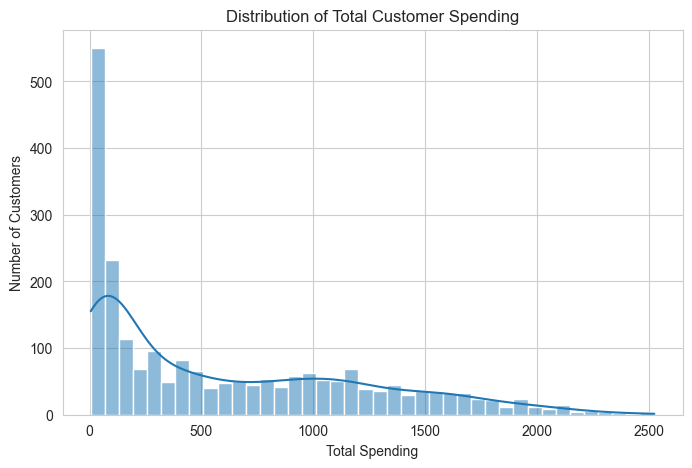

In [21]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Total_Spending",
    bins=40,
    kde=True
)

plt.title("Distribution of Total Customer Spending")
plt.xlabel("Total Spending")
plt.ylabel("Number of Customers")

plt.show()

### Purchase Channel EDA

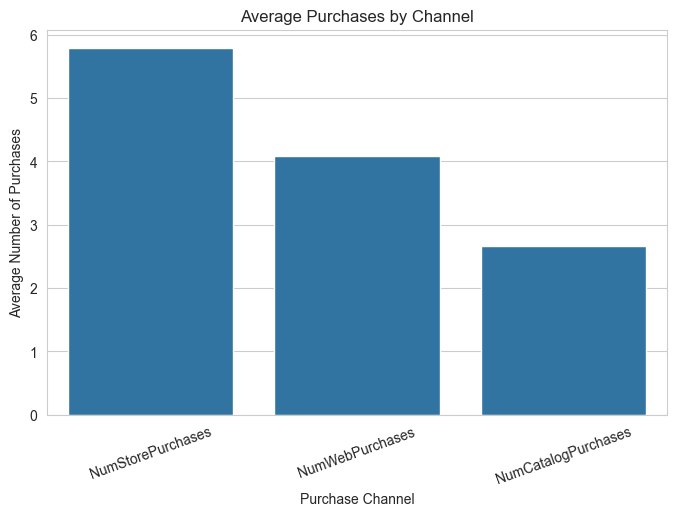

In [22]:
channel_means = df[purchase_cols].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=channel_means.index,
    y=channel_means.values
)

plt.title("Average Purchases by Channel")
plt.xlabel("Purchase Channel")
plt.ylabel("Average Number of Purchases")

plt.xticks(rotation=20)

plt.show()

### Website Visits

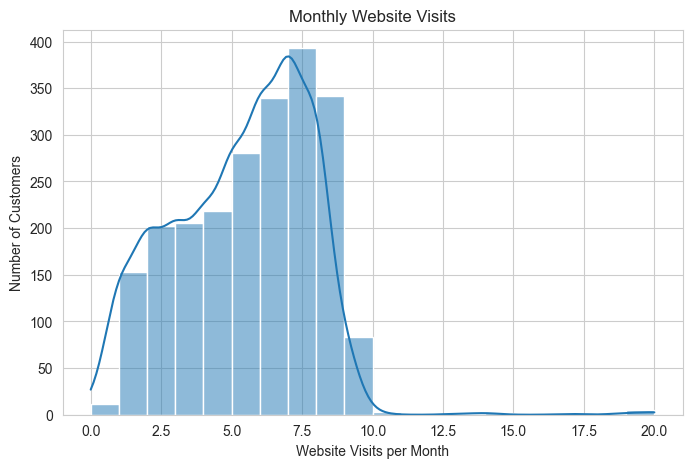

In [23]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="NumWebVisitsMonth",
    bins=20,
    kde=True
)

plt.title("Monthly Website Visits")
plt.xlabel("Website Visits per Month")
plt.ylabel("Number of Customers")

plt.show()

### Promotion EDA

In [24]:
campaign_response_rate = df[campaign_cols].mean() * 100

campaign_response_rate

AcceptedCmp1     6.428571
AcceptedCmp2     1.339286
AcceptedCmp3     7.276786
AcceptedCmp4     7.455357
AcceptedCmp5     7.276786
Response        14.910714
dtype: float64

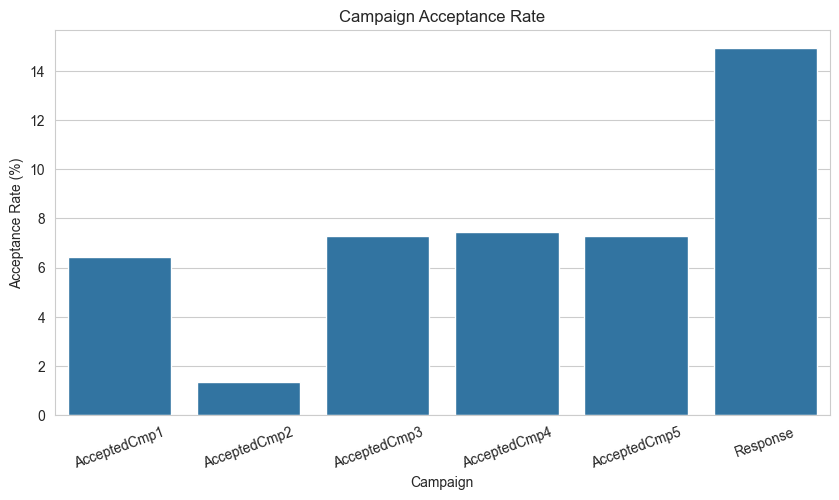

In [25]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=campaign_response_rate.index,
    y=campaign_response_rate.values
)

plt.title("Campaign Acceptance Rate")
plt.xlabel("Campaign")
plt.ylabel("Acceptance Rate (%)")

plt.xticks(rotation=20)

plt.show()

### Latest Campaign Response

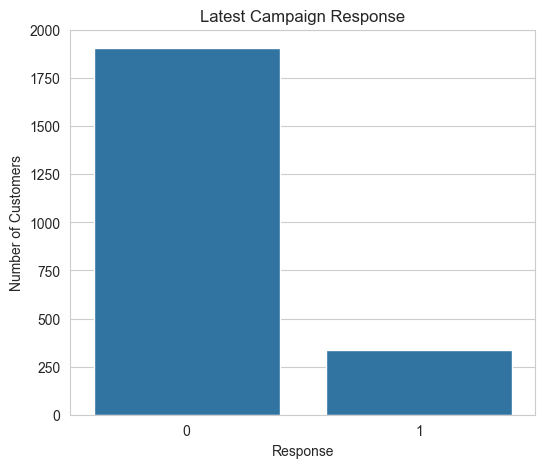

In [26]:
response_counts = df["Response"].value_counts()

plt.figure(figsize=(6, 5))

sns.barplot(
    x=response_counts.index.astype(str),
    y=response_counts.values
)

plt.title("Latest Campaign Response")
plt.xlabel("Response")
plt.ylabel("Number of Customers")

plt.show()

### Recency Analysis

In [27]:
#### Recency is an inverse measure of customer activity. How recently are customers purchasing?

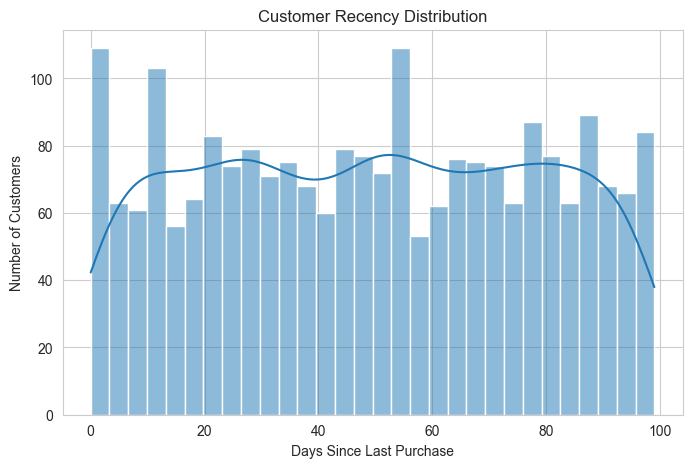

In [28]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Recency",
    bins=30,
    kde=True
)

plt.title("Customer Recency Distribution")
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Number of Customers")

plt.show()

### Correlation Analysis

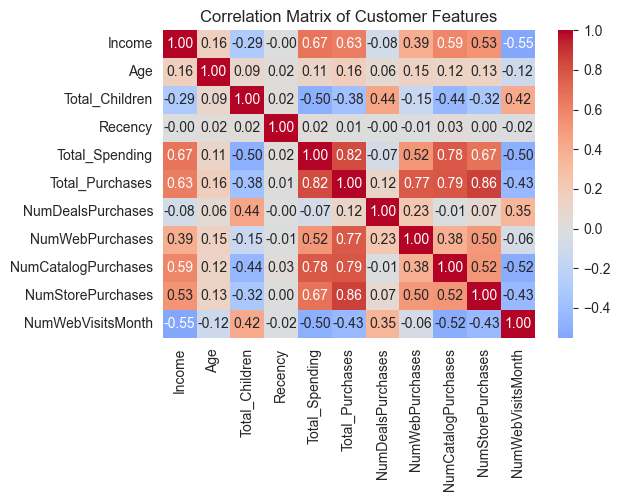

In [29]:
correlation_cols = [
    "Income",
    "Age",
    "Total_Children",
    "Recency",
    "Total_Spending",
    "Total_Purchases",
    "NumDealsPurchases",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "NumWebVisitsMonth"
]

correlation_matrix = df[correlation_cols].corr()

plt.figure(figsize=(6, 4))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Customer Features")

plt.show()

In [30]:
# Create a separate copy for preprocessing
cluster_df = df.copy()

print("Original shape:", cluster_df.shape)

Original shape: (2240, 34)


### Handle Missing Income

In [31]:
print("Missing Income before imputation:",
      cluster_df["Income"].isnull().sum())

income_median = cluster_df["Income"].median()

cluster_df["Income"] = cluster_df["Income"].fillna(income_median)

print("Missing Income after imputation:",
      cluster_df["Income"].isnull().sum())

Missing Income before imputation: 24
Missing Income after imputation: 0


### Check Age Outliers

In [32]:
cluster_df[cluster_df["Age"] > 100][
    ["ID", "Year_Birth", "Age", "Income"]
]

,ID,Year_Birth,Age,Income
192,7829,1900,114,36640.0
239,11004,1893,121,60182.0
339,1150,1899,115,83532.0


In [33]:
cluster_df["Age"] = cluster_df["Age"].clip(upper=90)# we'll use 90 years as the upper age boundary

cluster_df["Age"].describe()

count    2240.000000
mean       45.158482
std        11.808861
min        18.000000
25%        37.000000
50%        44.000000
75%        55.000000
max        90.000000
Name: Age, dtype: float64

### Investigate Income Outliers

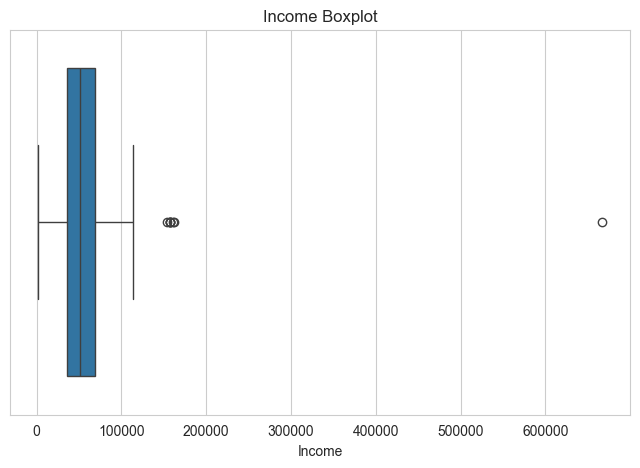

In [34]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=cluster_df["Income"])

plt.title("Income Boxplot")
plt.xlabel("Income")

plt.show()

In [35]:
cluster_df[
    cluster_df["Income"] > 200000
][["ID", "Income"]]

,ID,Income
2233,9432,666666.0


In [36]:
income_upper_limit = cluster_df["Income"].quantile(0.99)

print("99th percentile income:", income_upper_limit)

cluster_df["Income"] = cluster_df["Income"].clip(
    upper=income_upper_limit
)

99th percentile income: 94437.68000000001


In [37]:
cluster_df["Income"].describe()

count     2240.000000
mean     51751.681089
std      20648.623397
min       1730.000000
25%      35538.750000
50%      51381.500000
75%      68289.750000
max      94437.680000
Name: Income, dtype: float64

### Total Children

In [38]:
cluster_df["Total_Children"] = (
    cluster_df["Kidhome"] +
    cluster_df["Teenhome"]
)

### Total Spending

In [39]:
product_cols = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

cluster_df["Total_Spending"] = cluster_df[product_cols].sum(axis=1)

### Total Purchases

In [40]:
purchase_cols = [
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases"
]

cluster_df["Total_Purchases"] = cluster_df[purchase_cols].sum(axis=1)

### Total Campaign Acceptance

In [41]:
campaign_cols = [
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "Response"
]

cluster_df["Total_Campaign_Acceptance"] = (
    cluster_df[campaign_cols].sum(axis=1)
)

In [42]:
cluster_df["Dt_Customer"] = pd.to_datetime(
    cluster_df["Dt_Customer"],
    dayfirst=True
)

cluster_df["Dt_Customer"].head()

0   2012-09-04
1   2014-03-08
2   2013-08-21
3   2014-02-10
4   2014-01-19
Name: Dt_Customer, dtype: datetime64[us]

In [43]:
reference_date = cluster_df["Dt_Customer"].max()

cluster_df["Customer_Tenure_Days"] = (
    reference_date - cluster_df["Dt_Customer"]
).dt.days

cluster_df["Customer_Tenure_Days"].describe()

count    2240.000000
mean      353.582143
std       202.122512
min         0.000000
25%       180.750000
50%       355.500000
75%       529.000000
max       699.000000
Name: Customer_Tenure_Days, dtype: float64

In [44]:
new_features = [
    "Age",
    "Income",
    "Total_Children",
    "Total_Spending",
    "Total_Purchases",
    "Total_Campaign_Acceptance",
    "Customer_Tenure_Days",
    "Recency"
]

cluster_df[new_features].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,2240.0,45.158482,11.808861,18.0,37.00,44.0,55.00,90.00
Income,2240.0,51751.681089,20648.623397,1730.0,35538.75,51381.5,68289.75,94437.68
Total_Children,2240.0,0.950446,0.751803,0.0,0.00,1.0,1.00,3.00
Total_Spending,2240.0,605.798214,602.249288,5.0,68.75,396.0,1045.50,2525.00
Total_Purchases,2240.0,12.537054,7.205741,0.0,6.00,12.0,18.00,32.00
Total_Campaign_Acceptance,2240.0,0.446875,0.890543,0.0,0.00,0.0,1.00,5.00
Customer_Tenure_Days,2240.0,353.582143,202.122512,0.0,180.75,355.5,529.00,699.00
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.00


In [45]:
cluster_df = cluster_df.drop(columns=["ID"])

In [46]:
constant_columns = [
    col for col in cluster_df.columns
    if cluster_df[col].nunique() <= 1
]

print("Constant columns:", constant_columns)

Constant columns: ['Z_CostContact', 'Z_Revenue']


In [47]:
cluster_df = cluster_df.drop(columns=constant_columns)

print("Remaining columns:", cluster_df.shape[1])

Remaining columns: 32


### Select Clustering Features

In [48]:
clustering_features = [
    "Income",
    "Age",
    "Total_Children",
    "Recency",
    "Total_Spending",
    "Total_Purchases",
    "NumDealsPurchases",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "NumWebVisitsMonth",
    "Total_Campaign_Acceptance"
]

In [49]:
X = cluster_df[clustering_features].copy()

print("Clustering dataset shape:", X.shape)

X.head()

Clustering dataset shape: (2240, 12)


,Income,Age,Total_Children,Recency,Total_Spending,Total_Purchases,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Total_Campaign_Acceptance
0,58138.0,57,0,58,1617,22,3,8,10,4,7,1
1,46344.0,60,2,38,27,4,2,1,1,2,5,0
2,71613.0,49,0,26,776,20,1,8,2,10,4,0
3,26646.0,30,1,26,53,6,2,2,0,4,6,0
4,58293.0,33,1,94,422,14,5,5,3,6,5,0


In [50]:
X.isnull().sum()

Income                       0
Age                          0
Total_Children               0
Recency                      0
Total_Spending               0
Total_Purchases              0
NumDealsPurchases            0
NumWebPurchases              0
NumCatalogPurchases          0
NumStorePurchases            0
NumWebVisitsMonth            0
Total_Campaign_Acceptance    0
dtype: int64

### Check Distributions

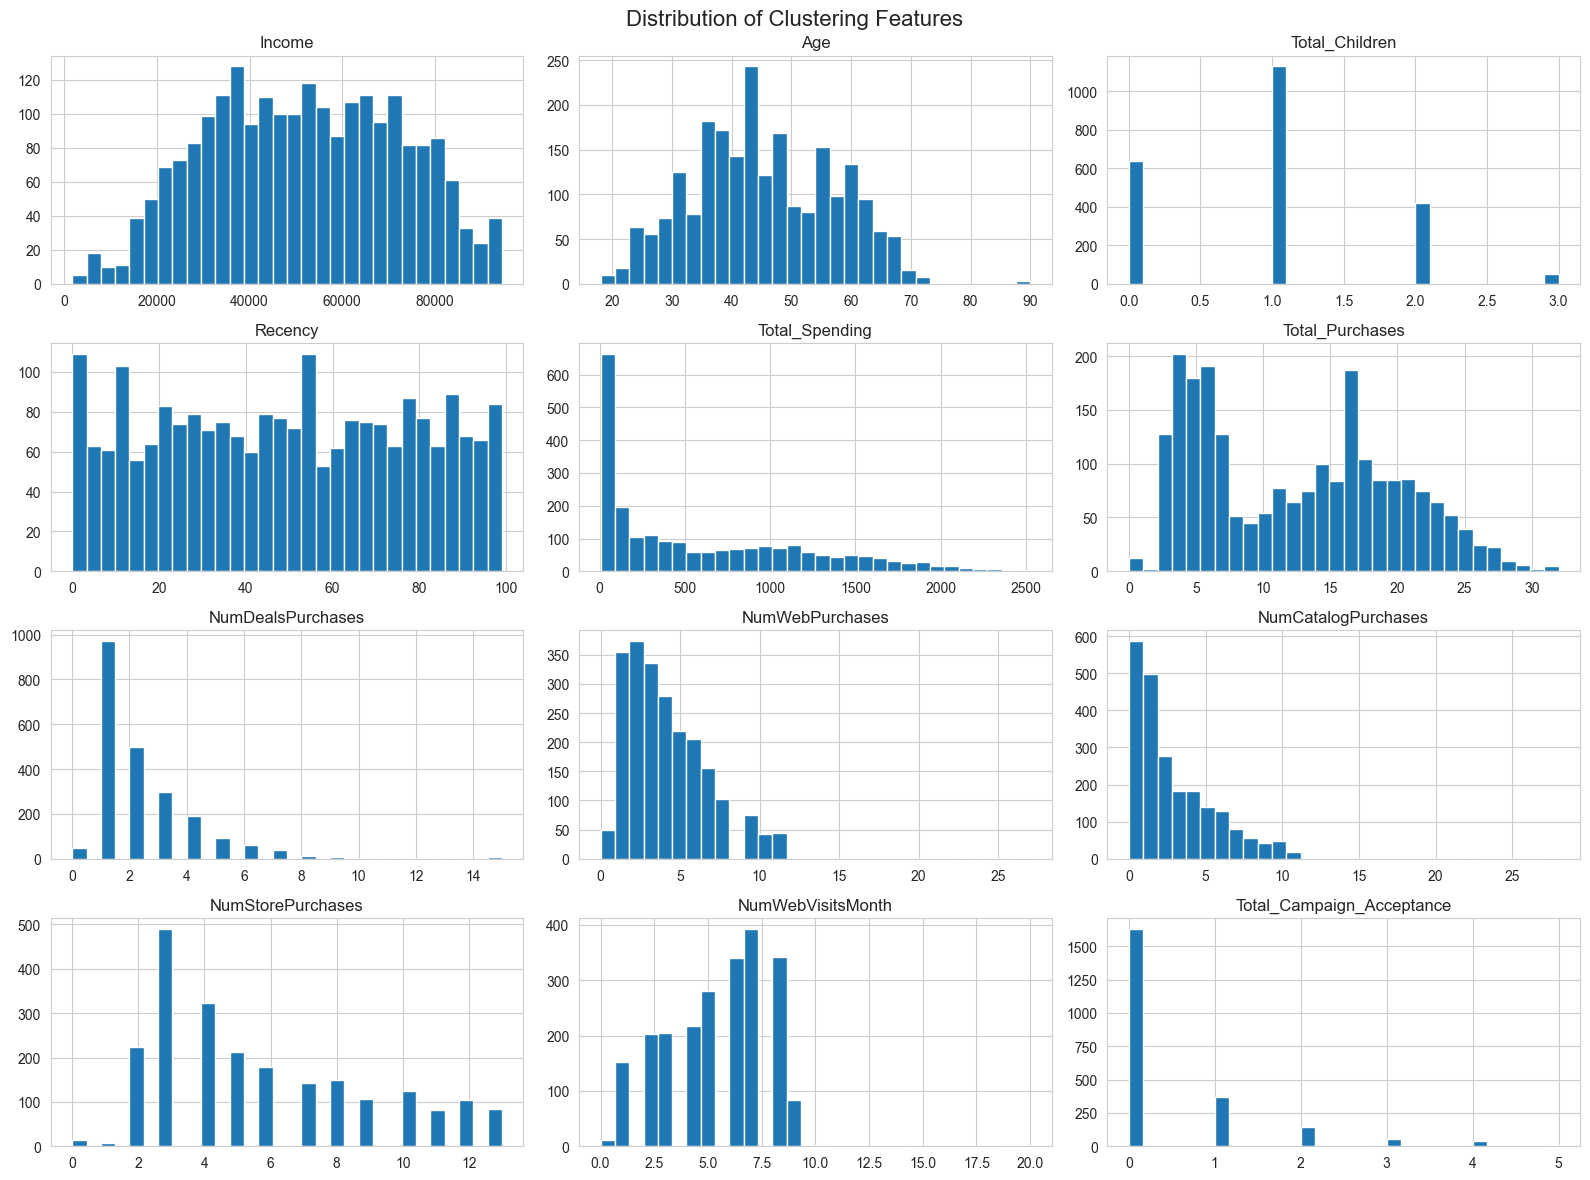

In [51]:
X.hist(
    figsize=(16, 12),
    bins=30
)

plt.suptitle(
    "Distribution of Clustering Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

### Scaling

In [52]:
from sklearn.preprocessing import StandardScaler

In [53]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=clustering_features,
    index=X.index
)

X_scaled.head()

,Income,Age,Total_Children,Recency,Total_Spending,Total_Purchases,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Total_Campaign_Acceptance
0,0.309355,1.002989,-1.264505,0.307039,1.679417,1.313544,0.349414,1.409304,2.510890,-0.550785,0.693904,0.621248
1,-0.261949,1.257093,1.396361,-0.383664,-0.961275,-1.185022,-0.168236,-1.110409,-0.568720,-1.166125,-0.130463,-0.501912
2,0.962086,0.325381,-1.264505,-0.798086,0.282673,1.035926,-0.685887,1.409304,-0.226541,1.295237,-0.542647,-0.501912
3,-1.216124,-1.283940,0.065928,-0.798086,-0.918094,-0.907403,-0.168236,-0.750450,-0.910898,-0.550785,0.281720,-0.501912
4,0.316863,-1.029837,0.065928,1.550305,-0.305254,0.203070,1.384715,0.329427,0.115638,0.064556,-0.130463,-0.501912


In [54]:
scaling_check = pd.DataFrame({
    "Mean": X_scaled.mean(),
    "Standard_Deviation": X_scaled.std()
})

scaling_check.round(3)

,Mean,Standard_Deviation
Income,0.0,1.0
Age,-0.0,1.0
Total_Children,0.0,1.0
Recency,-0.0,1.0
Total_Spending,0.0,1.0
Total_Purchases,-0.0,1.0
NumDealsPurchases,-0.0,1.0
NumWebPurchases,-0.0,1.0
NumCatalogPurchases,0.0,1.0
NumStorePurchases,0.0,1.0


In [55]:
print("Original dataset shape:", df.shape)
print("Clustering dataset shape:", X.shape)
print("Scaled dataset shape:", X_scaled.shape)

print("\nMissing values:")
print(X_scaled.isnull().sum().sum())

print("\nFeatures used for clustering:")
for feature in clustering_features:
    print("-", feature)

Original dataset shape: (2240, 34)
Clustering dataset shape: (2240, 12)
Scaled dataset shape: (2240, 12)

Missing values:
0

Features used for clustering:
- Income
- Age
- Total_Children
- Recency
- Total_Spending
- Total_Purchases
- NumDealsPurchases
- NumWebPurchases
- NumCatalogPurchases
- NumStorePurchases
- NumWebVisitsMonth
- Total_Campaign_Acceptance


### K-Means Clustering

In [56]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt

In [57]:
k_values = range(2, 11)

inertia_values = []
silhouette_values = []

for k in k_values:
    
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    cluster_labels = kmeans.fit_predict(X_scaled)
    
    inertia_values.append(kmeans.inertia_)
    
    silhouette_values.append(
        silhouette_score(X_scaled, cluster_labels)
    )

results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette_Score": silhouette_values
})

results

,K,Inertia,Silhouette_Score
0,2,17736.552663,0.315928
1,3,15346.987045,0.252324
2,4,14206.300470,0.246614
3,5,13267.570355,0.163764
4,6,12410.325304,0.160682
5,7,11797.169570,0.163388
6,8,11331.157837,0.148758
7,9,10959.345679,0.142742
8,10,10660.226607,0.141531


### Elbow Method

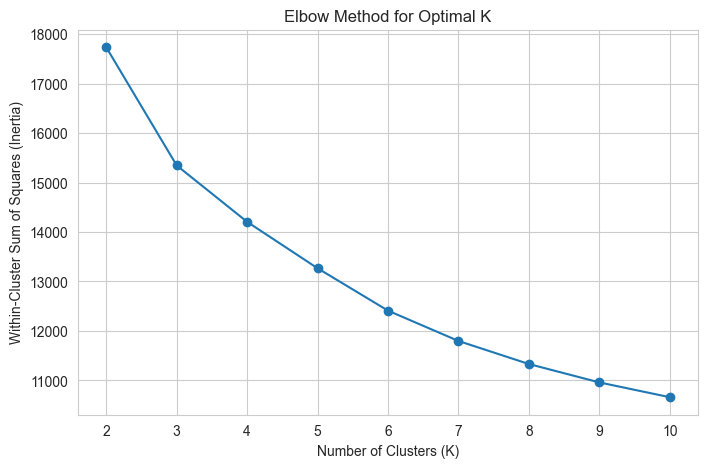

In [58]:
plt.figure(figsize=(8, 5))

plt.plot(
    results["K"],
    results["Inertia"],
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (Inertia)")
plt.xticks(results["K"])

plt.show()

### Silhouette Score

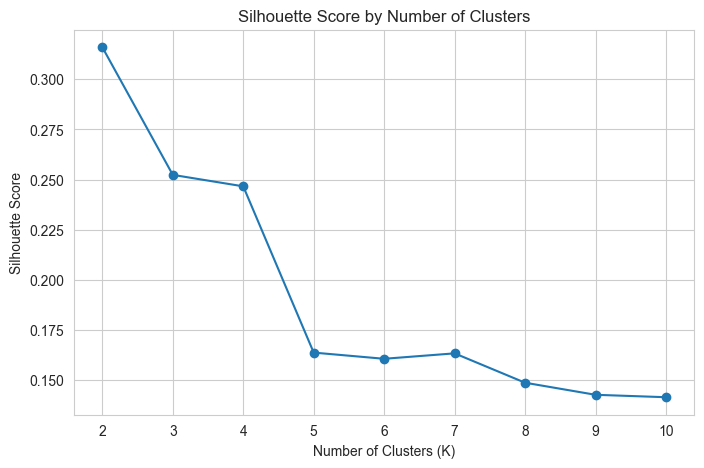

In [59]:
plt.figure(figsize=(8, 5))

plt.plot(
    results["K"],
    results["Silhouette_Score"],
    marker="o"
)

plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(results["K"])

plt.show()

In [60]:
results.sort_values(
    "Silhouette_Score",
    ascending=False
)

,K,Inertia,Silhouette_Score
0,2,17736.552663,0.315928
1,3,15346.987045,0.252324
2,4,14206.300470,0.246614
3,5,13267.570355,0.163764
5,7,11797.169570,0.163388
4,6,12410.325304,0.160682
6,8,11331.157837,0.148758
7,9,10959.345679,0.142742
8,10,10660.226607,0.141531


In [61]:
best_k_silhouette = results.loc[
    results["Silhouette_Score"].idxmax(),
    "K"
]

print("K with highest Silhouette Score:",
      best_k_silhouette)

K with highest Silhouette Score: 2


In [62]:
optimal_k = 4

final_kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

cluster_labels = final_kmeans.fit_predict(X_scaled)

In [63]:
cluster_df["Cluster"] = cluster_labels

cluster_df["Cluster"].value_counts().sort_index()

Cluster
0    1024
1     526
2     522
3     168
Name: count, dtype: int64

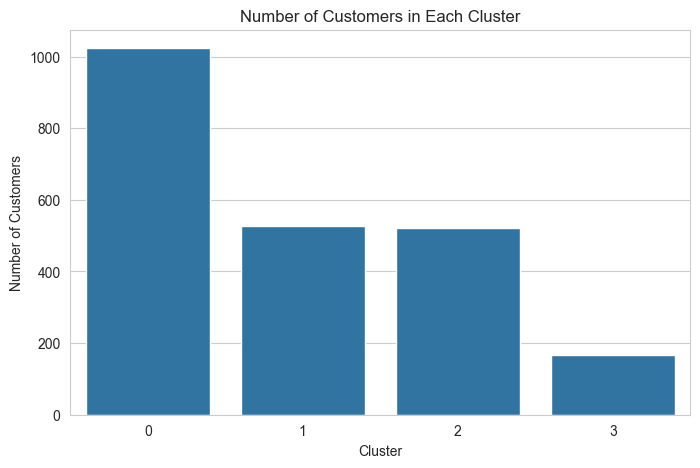

In [64]:
cluster_counts = (
    cluster_df["Cluster"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

plt.show()

In [65]:
final_silhouette = silhouette_score(
    X_scaled,
    cluster_labels
)

print(
    f"Final Silhouette Score: {final_silhouette:.4f}"
)

Final Silhouette Score: 0.2466


In [66]:
centroids = pd.DataFrame(
    final_kmeans.cluster_centers_,
    columns=clustering_features
)

centroids

,Income,Age,Total_Children,Recency,Total_Spending,Total_Purchases,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Total_Campaign_Acceptance
0,-0.822864,-0.215333,0.353062,0.010151,-0.848759,-0.942648,-0.199073,-0.738147,-0.726109,-0.805574,0.446352,-0.306676
1,0.983459,0.193659,-0.809224,0.078424,0.973837,0.921395,-0.449696,0.297263,1.019875,0.871167,-1.052783,-0.181619
2,0.186906,0.263396,0.445687,-0.058226,0.149862,0.589715,1.041598,0.950735,0.005512,0.489518,0.433328,-0.090948
3,1.355646,-0.112242,-1.003170,-0.126500,1.658706,1.028490,-0.615018,0.614394,1.215499,0.661583,-0.770820,2.720489


In [67]:
centroids_original = pd.DataFrame(
    scaler.inverse_transform(
        final_kmeans.cluster_centers_
    ),
    columns=clustering_features
)

centroids_original

,Income,Age,Total_Children,Recency,Total_Spending,Total_Purchases,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Total_Campaign_Acceptance
0,34764.466211,42.616211,1.215820,49.403320,94.748047,5.746094,1.940430,2.034180,0.540039,3.171875,6.399414,0.173828
1,72054.216540,47.444867,0.342205,51.380228,1192.159696,19.174905,1.456274,4.910646,5.642586,8.621673,2.762357,0.285171
2,55610.171801,48.268199,1.285441,47.423372,696.032567,16.785441,4.337165,6.726054,2.678161,7.381226,6.367816,0.365900
3,79737.646786,43.833333,0.196429,45.446429,1604.529762,19.946429,1.136905,5.791667,6.214286,7.940476,3.446429,2.869048


In [68]:
cluster_profile = (
    cluster_df
    .groupby("Cluster")[clustering_features]
    .mean()
    .round(2)
)

cluster_profile

,Income,Age,Total_Children,Recency,Total_Spending,Total_Purchases,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Total_Campaign_Acceptance
Cluster,,,,,,,,,,,,
0,34764.47,42.62,1.22,49.40,94.75,5.75,1.94,2.03,0.54,3.17,6.40,0.17
1,72054.22,47.44,0.34,51.38,1192.16,19.17,1.46,4.91,5.64,8.62,2.76,0.29
2,55610.17,48.27,1.29,47.42,696.03,16.79,4.34,6.73,2.68,7.38,6.37,0.37
3,79737.65,43.83,0.20,45.45,1604.53,19.95,1.14,5.79,6.21,7.94,3.45,2.87


In [69]:
cluster_profile["Customer_Count"] = (
    cluster_df["Cluster"]
    .value_counts()
    .sort_index()
)

cluster_profile

,Income,Age,Total_Children,Recency,Total_Spending,Total_Purchases,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Total_Campaign_Acceptance,Customer_Count
Cluster,,,,,,,,,,,,,
0,34764.47,42.62,1.22,49.40,94.75,5.75,1.94,2.03,0.54,3.17,6.40,0.17,1024
1,72054.22,47.44,0.34,51.38,1192.16,19.17,1.46,4.91,5.64,8.62,2.76,0.29,526
2,55610.17,48.27,1.29,47.42,696.03,16.79,4.34,6.73,2.68,7.38,6.37,0.37,522
3,79737.65,43.83,0.20,45.45,1604.53,19.95,1.14,5.79,6.21,7.94,3.45,2.87,168


In [70]:
cluster_profile["Customer_Percentage"] = (
    cluster_profile["Customer_Count"]
    / len(cluster_df)
    * 100
).round(2)

cluster_profile

,Income,Age,Total_Children,Recency,Total_Spending,Total_Purchases,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Total_Campaign_Acceptance,Customer_Count,Customer_Percentage
Cluster,,,,,,,,,,,,,,
0,34764.47,42.62,1.22,49.40,94.75,5.75,1.94,2.03,0.54,3.17,6.40,0.17,1024,45.71
1,72054.22,47.44,0.34,51.38,1192.16,19.17,1.46,4.91,5.64,8.62,2.76,0.29,526,23.48
2,55610.17,48.27,1.29,47.42,696.03,16.79,4.34,6.73,2.68,7.38,6.37,0.37,522,23.30
3,79737.65,43.83,0.20,45.45,1604.53,19.95,1.14,5.79,6.21,7.94,3.45,2.87,168,7.50


### Spending by Cluster

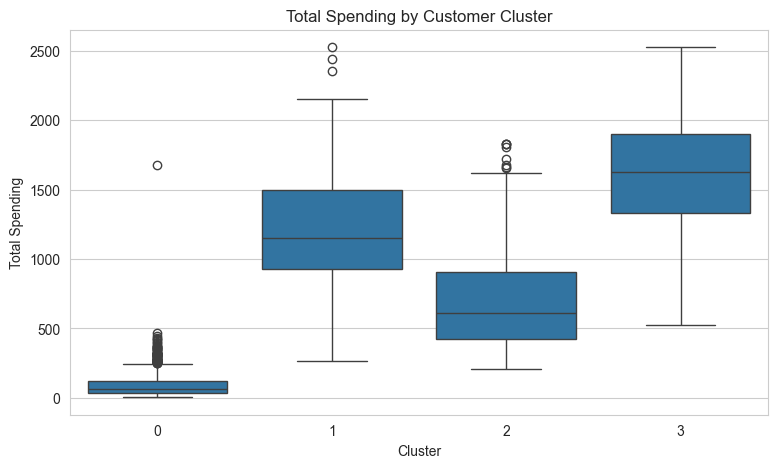

In [71]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=cluster_df,
    x="Cluster",
    y="Total_Spending"
)

plt.title("Total Spending by Customer Cluster")
plt.xlabel("Cluster")
plt.ylabel("Total Spending")

plt.show()

### Income by Cluster

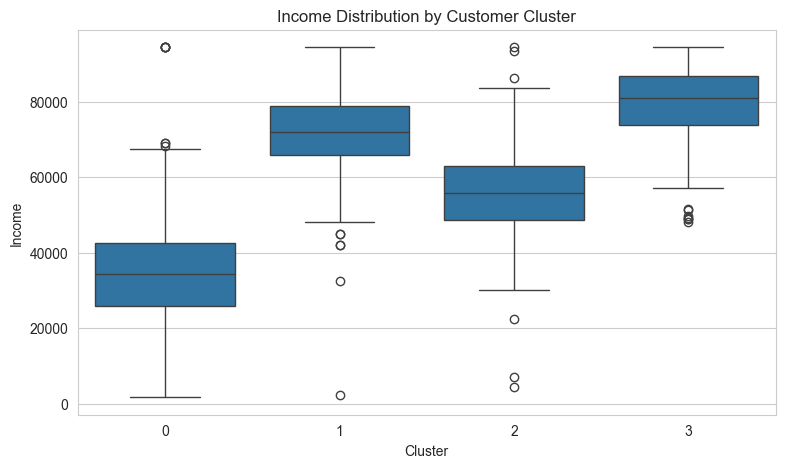

In [72]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=cluster_df,
    x="Cluster",
    y="Income"
)

plt.title("Income Distribution by Customer Cluster")
plt.xlabel("Cluster")
plt.ylabel("Income")

plt.show()

### Recency by Cluster

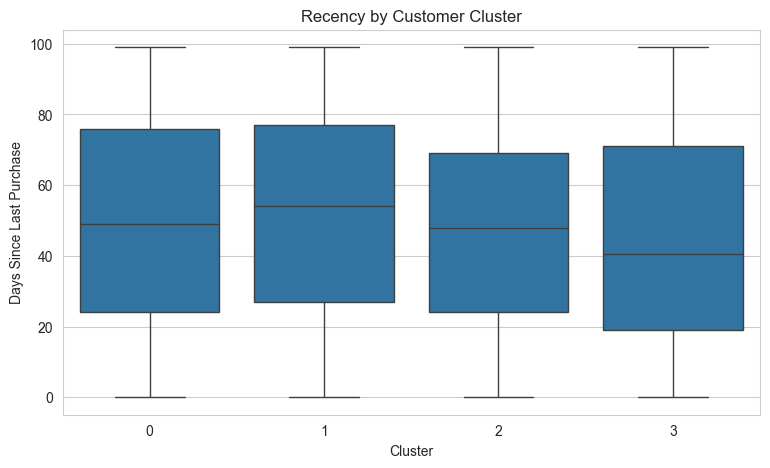

In [73]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=cluster_df,
    x="Cluster",
    y="Recency"
)

plt.title("Recency by Customer Cluster")
plt.xlabel("Cluster")
plt.ylabel("Days Since Last Purchase")

plt.show()

### Purchase Behavior by Cluster

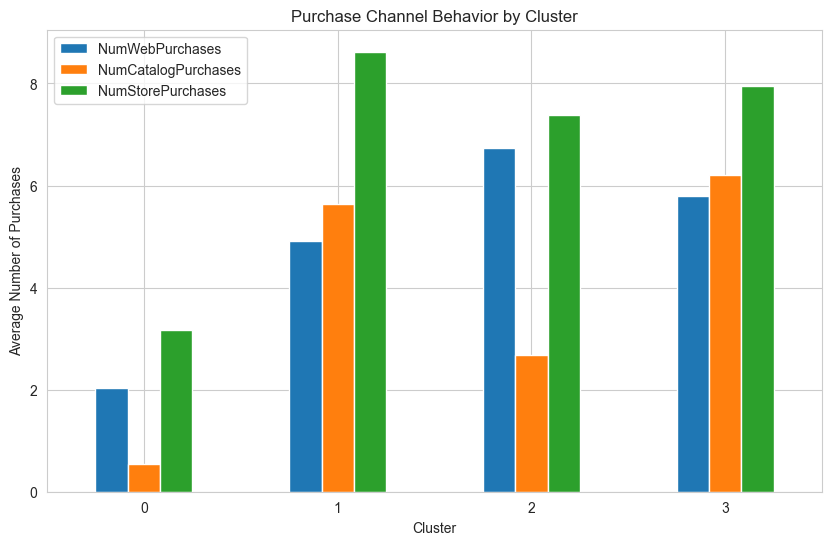

In [74]:
channel_profile = (
    cluster_df
    .groupby("Cluster")[
        [
            "NumWebPurchases",
            "NumCatalogPurchases",
            "NumStorePurchases"
        ]
    ]
    .mean()
)

channel_profile.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Purchase Channel Behavior by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Number of Purchases")

plt.xticks(rotation=0)

plt.show()

### Campaign Engagement by Cluster

In [75]:
campaign_profile = (
    cluster_df
    .groupby("Cluster")[
        [
            "AcceptedCmp1",
            "AcceptedCmp2",
            "AcceptedCmp3",
            "AcceptedCmp4",
            "AcceptedCmp5",
            "Response"
        ]
    ]
    .mean() * 100
)

campaign_profile.round(2)

,AcceptedCmp1,AcceptedCmp2,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,Response
Cluster,,,,,,
0,0.10,0.20,7.13,1.37,0.00,8.59
1,6.08,0.00,2.28,3.42,7.22,9.51
2,2.68,0.96,6.70,12.45,0.77,13.03
3,57.74,13.69,25.60,41.67,72.02,76.19


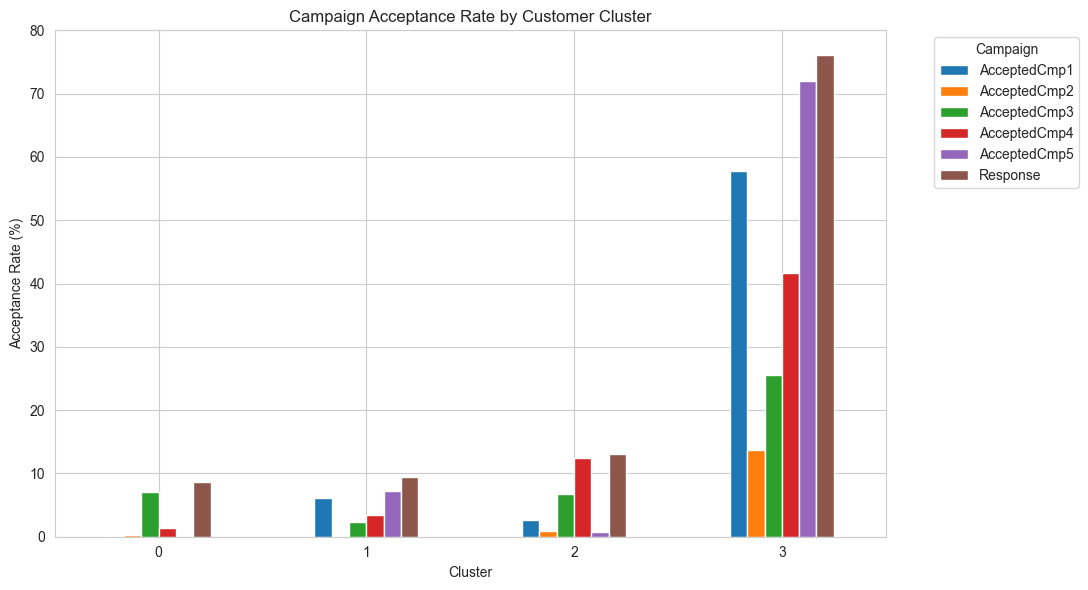

In [76]:
campaign_profile.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Campaign Acceptance Rate by Customer Cluster")
plt.xlabel("Cluster")
plt.ylabel("Acceptance Rate (%)")

plt.xticks(rotation=0)

plt.legend(
    title="Campaign",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

#### Hierarchical Clustering

In [77]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

## Create the dendrogram

In [78]:
X_scaled

,Income,Age,Total_Children,Recency,Total_Spending,Total_Purchases,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Total_Campaign_Acceptance
0,0.309355,1.002989,-1.264505,0.307039,1.679417,1.313544,0.349414,1.409304,2.510890,-0.550785,0.693904,0.621248
1,-0.261949,1.257093,1.396361,-0.383664,-0.961275,-1.185022,-0.168236,-1.110409,-0.568720,-1.166125,-0.130463,-0.501912
2,0.962086,0.325381,-1.264505,-0.798086,0.282673,1.035926,-0.685887,1.409304,-0.226541,1.295237,-0.542647,-0.501912
3,-1.216124,-1.283940,0.065928,-0.798086,-0.918094,-0.907403,-0.168236,-0.750450,-0.910898,-0.550785,0.281720,-0.501912
4,0.316863,-1.029837,0.065928,1.550305,-0.305254,0.203070,1.384715,0.329427,0.115638,0.064556,-0.130463,-0.501912
...,...,...,...,...,...,...,...,...,...,...,...,...
2235,0.458793,0.155979,0.065928,-0.107383,1.221032,0.480689,-0.168236,1.769263,0.115638,-0.550785,-0.130463,-0.501912
2236,0.593989,1.934701,2.726794,0.237969,-0.268717,0.341880,2.420015,1.409304,-0.226541,-0.243114,0.693904,0.621248
2237,0.253309,-1.029837,-1.264505,1.446700,1.054951,0.758307,-0.685887,-0.750450,0.115638,2.218248,0.281720,0.621248
2238,0.847380,1.087690,0.065928,-1.419719,0.393948,1.174735,-0.168236,0.689386,0.799996,1.295237,-0.954831,-0.501912


In [79]:
linkage_matrix = linkage(
    X_scaled,
    method="ward"
)

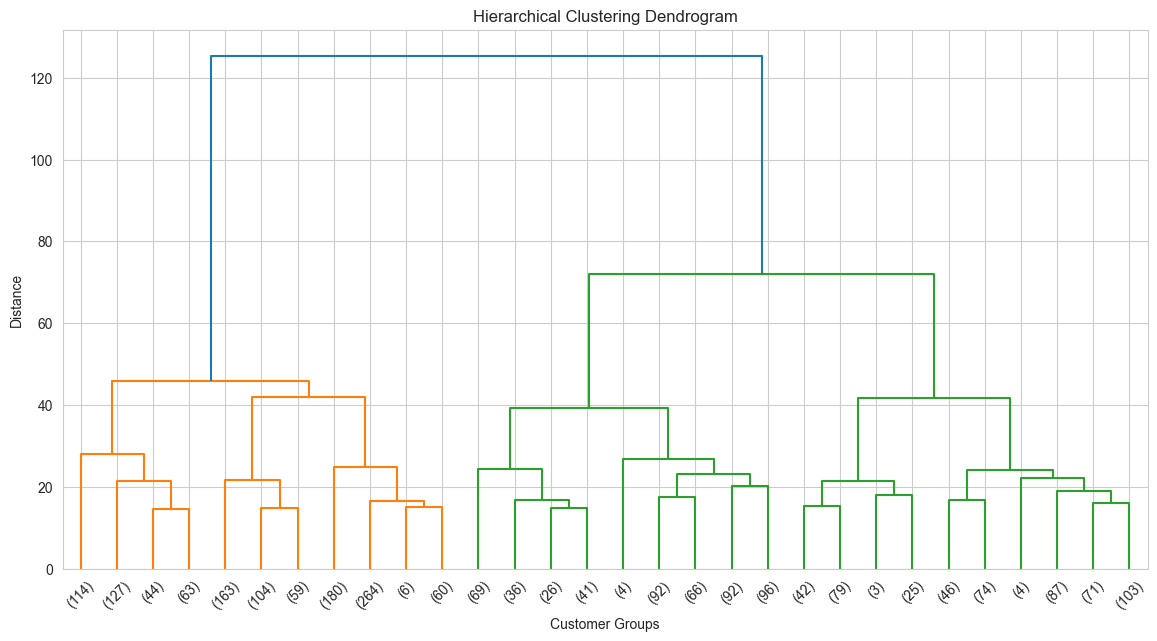

In [80]:
plt.figure(figsize=(14, 7))

dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=30
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Customer Groups")
plt.ylabel("Distance")

plt.show()

In [81]:
# The vertical axis represents distance.
# Smaller distance:Customers/groups are more similar.
# Larger distance:Customers/groups are more different.
# The dendrogram helps us decide where we could "cut" the hierarchy to create customer segments.

In [82]:
hierarchical_results = []

for k in range(2, 11):

    hierarchical_model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = hierarchical_model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    hierarchical_results.append({
        "K": k,
        "Silhouette_Score": score
    })

hierarchical_results = pd.DataFrame(
    hierarchical_results
)

hierarchical_results

,K,Silhouette_Score
0,2,0.274902
1,3,0.243631
2,4,0.144565
3,5,0.134979
4,6,0.134239
5,7,0.134305
6,8,0.130884
7,9,0.132704
8,10,0.104473


#### PLOT SILHOUETTE SCORE

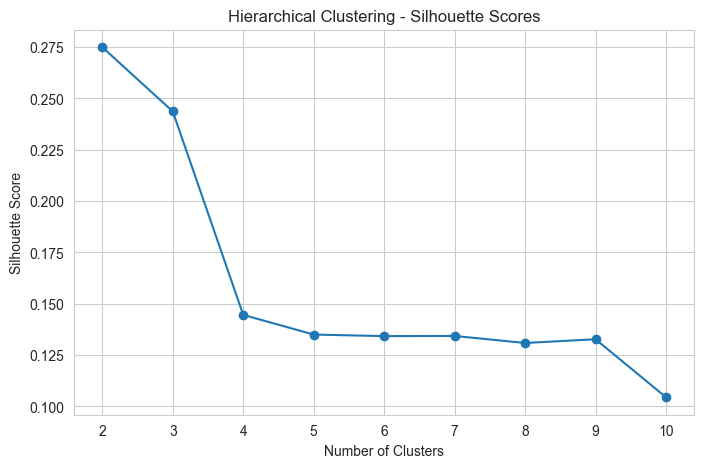

In [83]:
plt.figure(figsize=(8, 5))

plt.plot(
    hierarchical_results["K"],
    hierarchical_results["Silhouette_Score"],
    marker="o"
)

plt.title("Hierarchical Clustering - Silhouette Scores")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

#### Find the best Hierarchical K

In [84]:
best_hierarchical_k = int(
    hierarchical_results.loc[
        hierarchical_results["Silhouette_Score"].idxmax(),
        "K"
    ]
)

print(
    "Best K for Hierarchical Clustering:",
    best_hierarchical_k
)

Best K for Hierarchical Clustering: 2


In [85]:
best_hierarchical_score = hierarchical_results[
    hierarchical_results["K"] == best_hierarchical_k
]["Silhouette_Score"].iloc[0]

print(
    "Best Silhouette Score:",
    round(best_hierarchical_score, 3)
)

Best Silhouette Score: 0.275


#### Train the final Hierarchical model

In [86]:
hierarchical_model = AgglomerativeClustering(
    n_clusters=best_hierarchical_k,
    linkage="ward"
)

hierarchical_labels = hierarchical_model.fit_predict(X_scaled)

cluster_df["Hierarchical_Cluster"] = hierarchical_labels

hierarchical_sizes = (
    cluster_df["Hierarchical_Cluster"]
    .value_counts()
    .sort_index()
)

print(hierarchical_sizes)

In [87]:
hierarchical_sizes = (
    cluster_df["Hierarchical_Cluster"]
    .value_counts()
    .sort_index()
)

print(hierarchical_sizes)

Hierarchical_Cluster
0    1056
1    1184
Name: count, dtype: int64


In [88]:
hierarchical_percentage = (
    cluster_df["Hierarchical_Cluster"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
).round(2)

print(hierarchical_percentage)

Hierarchical_Cluster
0    47.14
1    52.86
Name: proportion, dtype: float64


In [89]:
hierarchical_profile = (
    cluster_df
    .groupby("Hierarchical_Cluster")[clustering_features]
    .mean()
    .round(2)
)

hierarchical_profile["Customer_Count"] = (
    cluster_df["Hierarchical_Cluster"]
    .value_counts()
    .sort_index()
)

hierarchical_profile["Customer_Percentage"] = (
    hierarchical_profile["Customer_Count"]
    / len(cluster_df)
    * 100
).round(2)

hierarchical_profile

,Income,Age,Total_Children,Recency,Total_Spending,Total_Purchases,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Total_Campaign_Acceptance,Customer_Count,Customer_Percentage
Hierarchical_Cluster,,,,,,,,,,,,,,
0,67406.23,47.11,0.69,51.18,1110.74,18.76,2.69,5.88,4.76,8.12,4.34,0.75,1056,47.14
1,37789.51,43.42,1.19,47.26,155.45,6.99,2.00,2.48,0.79,3.71,6.18,0.18,1184,52.86


##### The hierarchical clustering divided our customers into two distinct groups. Cluster 0 represents high-value customers who have higher income, significantly higher spending, and more purchases across web, catalog, and store channels. They also show stronger campaign engagement. Cluster 1 represents lower-value customers who spend considerably less and make fewer purchases. Interestingly, they visit the website more frequently but have fewer online purchases, which suggests an opportunity to improve conversion. Therefore, we can use different marketing strategies for each segment rather than treating all customers the same."

### DBSCAN Clustering

In [90]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [91]:
X_scaled.shape

(2240, 12)

In [92]:
eps = 1.0
min_samples = 5

#### Baseline DBSCAN

In [93]:
dbscan_baseline = DBSCAN(
    eps=1.0,
    min_samples=5
)

baseline_labels = dbscan_baseline.fit_predict(X_scaled)

In [94]:
df['DBSCAN_Baseline'] = baseline_labels

In [95]:
df['DBSCAN_Baseline'].value_counts().sort_index()

DBSCAN_Baseline
-1     1504
 0      420
 1        9
 2      193
 3        5
 4        7
 5        6
 6        7
 7        8
 8        7
 9       12
 10       5
 11       9
 12       7
 13      18
 14       5
 15       5
 16       5
 17       5
 18       3
Name: count, dtype: int64

In [96]:
neighbors = NearestNeighbors(n_neighbors=5)

neighbors_fit = neighbors.fit(X_scaled)

distances, indices = neighbors_fit.kneighbors(X_scaled)

# Distance to the 5th nearest neighbor
k_distances = distances[:, 4]

# Sort distances
k_distances = np.sort(k_distances)

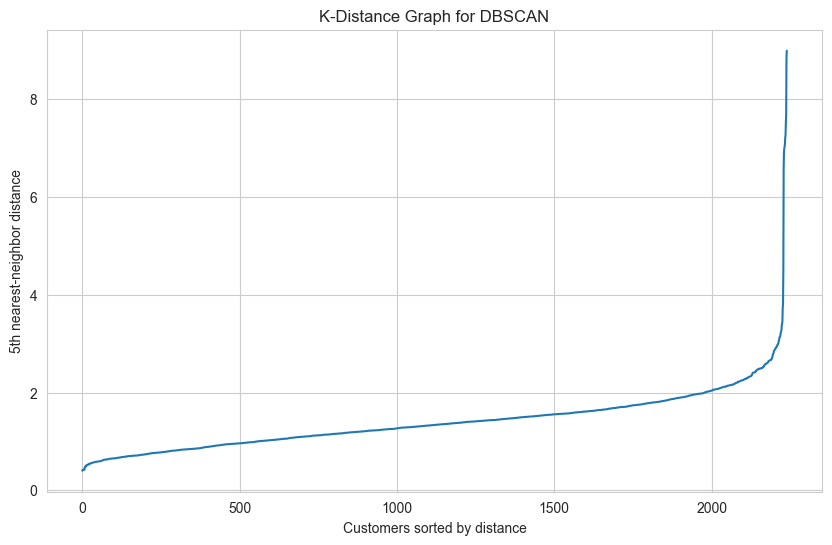

In [97]:
plt.figure(figsize=(10, 6))

plt.plot(k_distances)

plt.xlabel("Customers sorted by distance")
plt.ylabel("5th nearest-neighbor distance")
plt.title("K-Distance Graph for DBSCAN")

plt.grid(True)
plt.show()

In [98]:
eps_values = [1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 2.0]

results = []

for eps in eps_values:

    dbscan = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = dbscan.fit_predict(X_scaled)

    n_clusters = len(set(labels)) - (
        1 if -1 in labels else 0
    )

    n_noise = np.sum(labels == -1)

    noise_percentage = (
        n_noise / len(labels)
    ) * 100

    # Exclude noise for silhouette calculation
    mask = labels != -1

    if len(set(labels[mask])) >= 2:

        silhouette = silhouette_score(
            X_scaled[mask],
            labels[mask]
        )

    else:
        silhouette = np.nan

    results.append({
        "eps": eps,
        "clusters": n_clusters,
        "noise_points": n_noise,
        "noise_percentage": round(noise_percentage, 2),
        "silhouette": round(silhouette, 3)
    })

eps_results = pd.DataFrame(results)

eps_results

,eps,clusters,noise_points,noise_percentage,silhouette
0,1.2,19,1133,50.58,-0.088
1,1.3,19,912,40.71,-0.116
2,1.4,7,749,33.44,0.204
3,1.5,6,577,25.76,0.056
4,1.6,2,445,19.87,0.067
5,1.7,3,336,15.00,-0.082
6,1.8,1,242,10.80,NaN
7,2.0,2,139,6.21,0.346


In [99]:
eps_values = [1.2, 1.4, 1.6, 1.8, 2.0]

min_samples_values = [5, 10, 15, 20]

tuning_results = []

for min_samples in min_samples_values:

    for eps in eps_values:

        dbscan = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = dbscan.fit_predict(X_scaled)

        n_clusters = len(set(labels)) - (
            1 if -1 in labels else 0
        )

        n_noise = np.sum(labels == -1)

        noise_percentage = (
            n_noise / len(labels)
        ) * 100

        mask = labels != -1

        if (
            n_clusters >= 2
            and len(set(labels[mask])) >= 2
        ):

            silhouette = silhouette_score(
                X_scaled[mask],
                labels[mask]
            )

        else:

            silhouette = np.nan

        tuning_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "clusters": n_clusters,
            "noise_percentage": round(noise_percentage, 2),
            "silhouette": round(silhouette, 3)
        })

dbscan_tuning = pd.DataFrame(tuning_results)

dbscan_tuning.sort_values(
    by="silhouette",
    ascending=False
).head(15)

,eps,min_samples,clusters,noise_percentage,silhouette
16,1.4,20,2,62.81,0.408
11,1.4,15,3,54.46,0.359
4,2.0,5,2,6.21,0.346
17,1.6,20,2,38.79,0.319
6,1.4,10,3,45.94,0.309
15,1.2,20,2,74.24,0.225
1,1.4,5,7,33.44,0.204
10,1.2,15,3,70.58,0.138
5,1.2,10,7,65.18,0.067
2,1.6,5,2,19.87,0.067


#### Build the Final DBSCAN Model

In [100]:
dbscan_final = DBSCAN(
    eps=2.0,
    min_samples=5
)

dbscan_labels = dbscan_final.fit_predict(X_scaled)

In [101]:
df['DBSCAN_Cluster'] = dbscan_labels

In [102]:
cluster_counts = (
    df['DBSCAN_Cluster']
    .value_counts()
    .sort_index()
)

cluster_counts

DBSCAN_Cluster
-1     139
 0    2096
 1       5
Name: count, dtype: int64

In [103]:
cluster_percentages = (
    df['DBSCAN_Cluster']
    .value_counts(normalize=True)
    .sort_index() * 100
)

cluster_percentages.round(2)

DBSCAN_Cluster
-1     6.21
 0    93.57
 1     0.22
Name: proportion, dtype: float64

In [104]:
mask = dbscan_labels != -1

silhouette_dbscan = silhouette_score(
    X_scaled[mask],
    dbscan_labels[mask]
)

print(
    "DBSCAN Silhouette Score:",
    round(silhouette_dbscan, 3)
)

DBSCAN Silhouette Score: 0.346


In [105]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

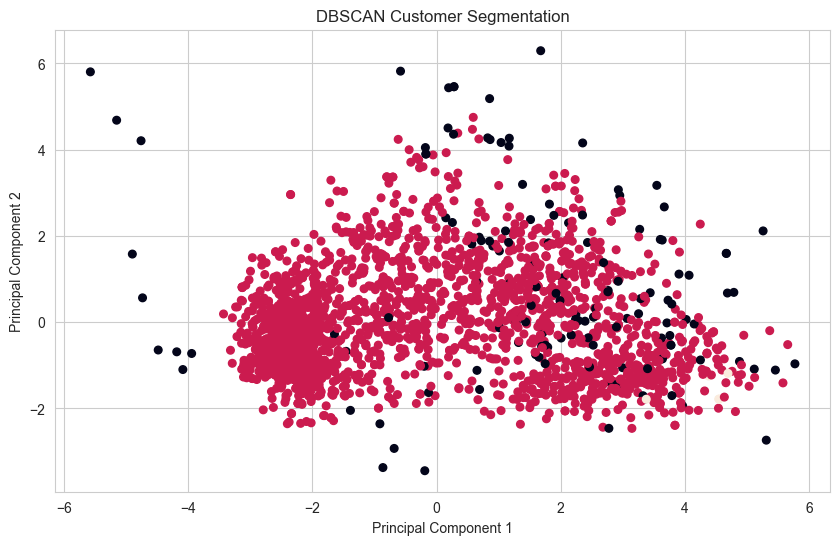

In [106]:
plt.figure(figsize=(10, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=dbscan_labels,
    s=30
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("DBSCAN Customer Segmentation")

plt.show()

In [107]:
dbscan_profile = df.groupby(
    'DBSCAN_Cluster'
).agg({
    'Income': 'mean',
    'Age': 'mean',
    'Total_Children': 'mean',
    'Recency': 'mean',
    'Total_Spending': 'mean',
    'Total_Purchases': 'mean',
    'NumDealsPurchases': 'mean',
    'NumWebPurchases': 'mean',
    'NumCatalogPurchases': 'mean',
    'NumStorePurchases': 'mean',
    'NumWebVisitsMonth': 'mean',
    'Total_Campaign_Acceptance': 'mean'
})

dbscan_profile

,Income,Age,Total_Children,Recency,Total_Spending,Total_Purchases,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Total_Campaign_Acceptance
DBSCAN_Cluster,,,,,,,,,,,,
-1,73527.828358,47.985612,0.942446,49.402878,1157.187050,17.517986,3.798561,5.762590,5.302158,6.453237,6.129496,1.661871
0,50785.946076,44.973760,0.953244,49.041985,566.301527,12.190840,2.231870,3.971374,2.471374,5.748092,5.269084,0.357347
1,88954.000000,60.000000,0.000000,69.200000,1834.200000,19.200000,0.400000,5.000000,9.200000,5.000000,2.600000,4.200000


###### After comparing K-Means, Hierarchical Clustering, and DBSCAN, Hierarchical Clustering was selected as the most appropriate method for this customer segmentation problem. Although DBSCAN achieved a slightly higher silhouette score of 0.346, it produced highly imbalanced clusters, with 93.57% of customers concentrated in one cluster and only 0.22% in another. Hierarchical Clustering produced two well-balanced groups, representing 47.14% and 52.86% of customers, with clearly different income, spending, purchase behavior, and campaign engagement. Therefore, Hierarchical Clustering provides the most interpretable and actionable customer segments for marketing decisions.

In [108]:
import joblib
import pandas as pd
from pathlib import Path

# Create a folder for deployment files
Path("deployment").mkdir(exist_ok=True)

# Calculate one representative point for each existing cluster
scaled_training_data = X_scaled.copy()
scaled_training_data["Hierarchical_Cluster"] = hierarchical_labels

cluster_centers = (
    scaled_training_data
    .groupby("Hierarchical_Cluster")[clustering_features]
    .mean()
)

artifacts = {
    "scaler": scaler,
    "features": clustering_features,
    "cluster_centers": cluster_centers,
    "income_upper_limit": income_upper_limit
}
joblib.dump(artifacts, "deployment/hierarchical_artifacts.pkl")

print("Deployment artifacts saved successfully!")
print(cluster_centers)

Deployment artifacts saved successfully!
                       Income       Age  Total_Children   Recency  \
Hierarchical_Cluster                                                
0                     0.75831  0.165203       -0.352352  0.071507   
1                    -0.67633 -0.147343        0.314260 -0.063776   

                      Total_Spending  Total_Purchases  NumDealsPurchases  \
Hierarchical_Cluster                                                       
0                           0.838611          0.86386           0.187648   
1                          -0.747951         -0.77047          -0.167362   

                      NumWebPurchases  NumCatalogPurchases  NumStorePurchases  \
Hierarchical_Cluster                                                            
0                            0.646777             0.717691           0.716607   
1                           -0.576855            -0.640103          -0.639136   

                      NumWebVisitsMonth  Total_Campa